In [8]:
import os, sys, math
# Runtime only: put the v6 repo dir on sys.path so `import modules` works from
# notebooks/. Editor go-to-definition comes from python.analysis.extraPaths.
_V6 = os.path.abspath(".." if os.path.isdir("../modules") else ".")
if _V6 not in sys.path:
    sys.path.insert(0, _V6)

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import modules  # noqa: F401 — sys.path injection

# A kernel keeps every module it has already imported in sys.modules, so editing a
# pipeline module on disk mid-session does NOT take effect on re-run. Reload the
# pipeline modules (dependencies first) so re-running this cell always tracks the
# current source -- see explore_trigger_counts.ipynb for the ImportError this
# guards against when a module has moved.
import importlib
for _m in ("modules.constants", "modules.geometry", "modules.layouts.strategies",
           "modules.surrogates", "modules.optimize"):
    if _m in sys.modules:
        importlib.reload(sys.modules[_m])

from modules.data import compute_labels_batch, place_clouds_enu
from modules.geometry import SurfaceUpMap, load_tr_mountain
from modules.layouts.strategies import _STRATEGIES, _STRATEGY_FNS
from modules.surrogates.fnn import encode_primary
from modules.surrogates.dual import load_dual_surrogate
from modules.optimize import LAYOUT_THRESHOLD
from modules.constants import (
    GEOMETRY_PATH_RESOLVED, GEOMETRY_GROUP, DET_KEY,
    EAST_ENTRY, LAYER_EAST_DX, N_PLANES, N_DETECTORS, SIGMA_SPATIAL,
    DUAL_SHOWER_CACHE_PATH, DUAL_POSITIONS_PATH, DUAL_SPECIES_IDS_PATH,
    LOG_E_MIN, LOG_E_MAX, T_LOG_SCALE, FNN_FOLDER,
)
import showerdata

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'device={DEVICE}  LAYOUT_THRESHOLD={LAYOUT_THRESHOLD}  SIGMA_SPATIAL={SIGMA_SPATIAL}')

mountain = load_tr_mountain(GEOMETRY_PATH_RESOLVED, GEOMETRY_GROUP, DET_KEY,
                            east_entry=EAST_ENTRY, layer_east_dx=LAYER_EAST_DX,
                            n_planes=N_PLANES)
surface  = SurfaceUpMap.from_mountain(mountain, grid_h=256, grid_w=256).to(DEVICE)
_mE, _mN, _mU = (mountain.centroids_ENU[:, i] for i in range(3))
print(f'mountain  East=[{_mE.min():.0f}, {_mE.max():.0f}]  North=[{_mN.min():.0f}, {_mN.max():.0f}]'
      f'  Up=[{_mU.min():.0f}, {_mU.max():.0f}]')

# ── Stage 2: the CURRENT trained surrogate checkpoint ────────────────────────
# load_dual_surrogate reads fnn_<species>.pt for every entry in SPECIES_NAMES out
# of FNN_FOLDER (modules.constants.RUN_LOCATION's run) and prints each
# checkpoint's own path + mtime as it loads -- that printed provenance line is
# what "current checkpoint" means in this notebook's title.
dual = load_dual_surrogate(FNN_FOLDER, DEVICE)
print(f"[dual] supports_var={dual.supports_var}  "
      f"(forward_sample below needs this True; falls back to the mean otherwise)")


device=cpu  LAYOUT_THRESHOLD=1.0  SIGMA_SPATIAL=50.0
mountain  East=[-498, 777]  North=[-956, 716]  Up=[2748, 3712]
[load] fnn_electron.pt  model=deepsets  epoch=101  val=0.06524199041298905
       /n/holylfs05/LABS/arguelles_delgado_lab/Everyone/zdimitrov/detector_optimization_v6/11_750k_max_100k_LBFGS/test_v6_run_02_recentered/fnn_electron.pt  mtime=2026-09-04 11:20
[load] fnn_muon.pt  model=deepsets  epoch=101  val=0.13016183917305063
       /n/holylfs05/LABS/arguelles_delgado_lab/Everyone/zdimitrov/detector_optimization_v6/11_750k_max_100k_LBFGS/test_v6_run_02_recentered/fnn_muon.pt  mtime=2026-09-04 13:29
[load] fnn_photon.pt  model=deepsets  epoch=101  val=0.08449021540766442
       /n/holylfs05/LABS/arguelles_delgado_lab/Everyone/zdimitrov/detector_optimization_v6/11_750k_max_100k_LBFGS/test_v6_run_02_recentered/fnn_photon.pt  mtime=2026-09-04 17:08
[dual] supports_var=True  (forward_sample below needs this True; falls back to the mean otherwise)


## Pick a diverse set of showers

Stage 2 (`02_train_fnn_deepsets.py`) predicts detector response from a **primary
encoding + a layout** — `dual.forward(primary, xy) -> (E, T)` — it never sees the raw
shower point cloud. So the primaries themselves come from lightweight metadata
(`showerdata.load_inc_particles`: direction, energy, EM/hadronic class), the same call
`modules.data.dataset_builder._load_corpus_metadata` makes to build `primary.pt` in Step 1
— no need to stream `explore_trigger_counts.ipynb`'s heavy point-cloud tensors for that.

The **screen** below picks the same six representative showers as that notebook, angle for
angle (see the next cell): it re-scores the identical `N_SHOWERS_NB` slice on the plane-aware
kernel, not the surrogate, so `df_show`'s shower indices — and therefore θ, φ — come out
identical. Only the coloured *prediction* in the figures further down is the surrogate's;
the choice of which six events to look at is not.


In [9]:
N_SHOWERS_NB = 300            # showers pulled into the notebook

# Metadata only (direction, energy, EM/hadronic class) -- no point clouds.
meta = showerdata.load_inc_particles(DUAL_SHOWER_CACHE_PATH)
species_all = torch.load(DUAL_SPECIES_IDS_PATH)               # (M,) idx into SPECIES_NAMES
n_pairs = int((species_all == 0).sum())                       # electron-block size
sl = slice(0, min(N_SHOWERS_NB, n_pairs))

# The primary (direction/energy/EM-hadronic-class/decay-vertex) is shared by all
# species components of one physical event (§3.6 in docs/THEORY.md), so slicing
# just the electron block gives the same primaries every species would.
dirs   = torch.as_tensor(meta.directions[sl.start:sl.stop], dtype=torch.float32)
energs = torch.as_tensor(meta.energies[sl.start:sl.stop],   dtype=torch.float32).reshape(-1)
pdg    = torch.as_tensor(meta.pdg[sl.start:sl.stop],        dtype=torch.long)
positions_all = torch.load(DUAL_POSITIONS_PATH)                # (M,3) ENU East,North,Up
positions = positions_all[sl.start:sl.stop].float()             # (S,3) real decay vertices
dirs_u = dirs / dirs.norm(dim=1, keepdim=True).clamp(min=1e-12) # unit travel dirs

# Array centre from the mesh (modules.data.dataset_builder's own convention),
# not a constant, so encode_primary's rel_E/N/U tracks the current geometry.
array_center = torch.as_tensor(mountain.centroids_ENU, dtype=torch.float32).mean(dim=0)
primaries = encode_primary(dirs_u, energs, pdg, positions, array_center).to(DEVICE)  # (S, PRIMARY_DIM)
print(f'corpus: {n_pairs} pairs; encoded {tuple(primaries.shape)} primaries '
      f'(E {float(energs.min()):.2e}..{float(energs.max()):.2e} GeV)')


corpus: 572164 pairs; encoded (300, 8) primaries (E 1.07e+05..9.95e+06 GeV)


## Load point clouds for THIS slice only — to match `explore_trigger_counts.ipynb`'s screen

The lightweight metadata above is enough to run the surrogate, but not enough to
reproduce that notebook's kernel-based screen, which needs the actual point clouds
(`compute_labels_batch` operates on the shower point cloud, not a primary encoding). Loaded
here, placed at the real decay vertices exactly as `01_build_dataset_northeast.py` does, and
discarded once `df_show` is picked a few cells down — the reinit sweep and both figures
below never touch it again.


In [10]:
# Same fields explore_trigger_counts.ipynb's setup cell streams for this slice, kept to
# a SEPARATE cell (not the lightweight metadata cell above) since it exists only to
# reproduce that notebook's screen -- not needed by the surrogate itself.
sub_points = showerdata.load(DUAL_SHOWER_CACHE_PATH, start=sl.start, stop=sl.stop)
points = torch.as_tensor(sub_points.points, dtype=torch.float32)   # (S,P,5) NATIVE frame
del sub_points

bad = ~torch.isfinite(points).all(dim=-1)
if int(bad.sum()):
    points[bad] = 0.0
    print(f'[sanitize] zeroed {int(bad.sum())} non-finite points')
# Same placement Step 1 applies -- reuses this cell's own dirs_u/positions, so the
# clouds land exactly where explore_trigger_counts.ipynb's do for the same rows.
points = place_clouds_enu(points, positions, dirs_u,
                          east_entry=EAST_ENTRY, layer_east_dx=LAYER_EAST_DX)
print(f'[place] {points.shape[0]} clouds at real decay vertices (kernel screen only)')


[place] 300 clouds at real decay vertices (kernel screen only)


## Screen on a default grid layout, using the plane-aware KERNEL (not the surrogate)

Same screen as `explore_trigger_counts.ipynb`'s matching cell, same `rng_scan` seed and
grid layout — scored on the kernel so the six showers picked below are identical to that
notebook's, angle for angle. The surrogate only enters from the reinit sweep onward.


In [11]:
rng_scan = np.random.default_rng(42)
fn_grid  = _STRATEGY_FNS['layout_grid']
e_scan, n_scan = fn_grid(mountain, n_det=N_DETECTORS, rng=rng_scan)   # (East, North)
e_scan = e_scan.float().to(DEVICE); n_scan = n_scan.float().to(DEVICE)

scan_records = []
for s in range(points.shape[0]):                      # every loaded shower
    E, _ = compute_labels_batch(points[s:s+1].to(DEVICE), e_scan, n_scan, surface)
    E0 = E[0]
    # theta/phi in the pipeline's own convention -- see explore_trigger_counts.ipynb's
    # matching cell for why this reads directly off dirs_u.
    theta = float(torch.arccos(dirs_u[s, 2].clamp(-1.0, 1.0)).item())
    phi   = float(torch.atan2(dirs_u[s, 1], dirs_u[s, 0]).item())
    scan_records.append(dict(
        shower=s, E=float(energs[s].item()), theta_deg=math.degrees(theta),
        phi_deg=math.degrees(phi) % 360.0,
        n_trig=int((E0 > LAYOUT_THRESHOLD).sum().item()),   # above the 04 cut
        n_nonzero=int((E0 > 0).sum().item()),               # any response at all
        e_sum=float(E0.sum().item()),
        e_max=float(E0.max().item()),
    ))
df_scan = pd.DataFrame(scan_records)
n = len(df_scan)
print(f"scanned {n} showers on the default grid (kernel ground truth, matching "
      f"explore_trigger_counts.ipynb's screen exactly)")
print(f"  any detector > LAYOUT_THRESHOLD={LAYOUT_THRESHOLD}: "
      f"{int((df_scan.n_trig > 0).sum())}/{n} ({100*(df_scan.n_trig > 0).mean():.1f}%)")
print(f"  any nonzero detector response          : "
      f"{int((df_scan.n_nonzero > 0).sum())}/{n} ({100*(df_scan.n_nonzero > 0).mean():.1f}%)")
print(f"  max single-detector response over all  : {df_scan.e_max.max():.4g}")
df_scan[['E', 'theta_deg', 'phi_deg', 'n_trig', 'n_nonzero', 'e_sum']].describe()


scanned 300 showers on the default grid (kernel ground truth, matching explore_trigger_counts.ipynb's screen exactly)
  any detector > LAYOUT_THRESHOLD=1.0: 246/300 (82.0%)
  any nonzero detector response          : 281/300 (93.7%)
  max single-detector response over all  : 6.98e+05


,E,theta_deg,phi_deg,n_trig,n_nonzero,e_sum
count,3.000000e+02,300.000000,300.000000,300.000000,300.000000,3.000000e+02
mean,1.237861e+06,84.754198,121.040213,26.853333,79.180000,3.095364e+05
std,1.532674e+06,11.955181,59.314082,19.314987,29.272693,5.784604e+05
min,1.066225e+05,58.896940,24.999583,0.000000,0.000000,0.000000e+00
25%,3.393372e+05,76.900209,81.764698,7.750000,74.000000,1.021514e+02
50%,6.175660e+05,84.846649,113.632945,29.000000,93.000000,5.550397e+04
75%,1.393007e+06,91.388269,144.498755,40.000000,100.000000,3.884317e+05
max,9.948421e+06,119.394862,358.705356,79.000000,100.000000,4.168582e+06


## Pick 6 showers spanning E and θ, from those the kernel deposits a nonzero response for


In [12]:
# Screening on `n_trig > 0` would leave a thin (often empty) sample -- select on
# e_sum > 0 (the array actually deposits something) and report n_trig alongside,
# same rule explore_trigger_counts.ipynb uses -- this screen IS the kernel, see
# the cells above, so df_show comes out identical to that notebook's.
df_hit = df_scan[df_scan['e_sum'] > 0].copy()
print(f"{len(df_hit)}/{len(df_scan)} showers deposit a nonzero response; "
      f"{int((df_hit.n_trig > 0).sum())} of those clear LAYOUT_THRESHOLD")
if df_hit.empty:
    raise RuntimeError("no shower reached the array — raise N_SHOWERS_NB in the setup cell")

df_hit['logE'] = np.log10(df_hit['E'])
_qE  = min(3, df_hit['logE'].nunique())
_qth = min(2, df_hit['theta_deg'].nunique())
df_hit['E_bin']     = pd.qcut(df_hit['logE'], q=_qE,
                              labels=['Elow', 'Emid', 'Ehigh'][:_qE], duplicates='drop')
df_hit['theta_bin'] = pd.qcut(df_hit['theta_deg'], q=_qth,
                              labels=['vert', 'horiz'][:_qth], duplicates='drop')

selected = []
for E_b in df_hit['E_bin'].cat.categories:
    for th_b in df_hit['theta_bin'].cat.categories:
        sub = df_hit[(df_hit['E_bin'] == E_b) & (df_hit['theta_bin'] == th_b)]
        if not len(sub):
            continue
        # Prefer the strongest depositor in the cell so the pattern plots show signal.
        pick = sub.sort_values('e_sum', ascending=False).iloc[0]
        selected.append(dict(shower=int(pick['shower']), E=float(pick['E']),
                             theta_deg=float(pick['theta_deg']),
                             phi_deg=float(pick['phi_deg']),
                             n_trig_default=int(pick['n_trig']),
                             e_sum=float(pick['e_sum']),
                             tag=f'{E_b}/{th_b}'))
df_show = pd.DataFrame(selected)
del points   # only needed for the kernel screen above; the reinit sweep below
             # and both figures use the surrogate, never the point cloud
df_show


281/300 showers deposit a nonzero response; 246 of those clear LAYOUT_THRESHOLD


,shower,E,theta_deg,phi_deg,n_trig_default,e_sum,tag
0,126,3.827972e+05,69.647658,88.491589,79,9.222464e+05,Elow/vert
1,168,3.625571e+05,91.195006,140.660820,33,3.654512e+05,Elow/horiz
2,244,5.744648e+05,79.508675,58.394006,29,2.301821e+06,Emid/vert
3,1,9.682043e+05,85.852459,104.677177,38,1.023604e+06,Emid/horiz
4,46,1.191899e+06,74.036915,74.097963,68,3.326441e+06,Ehigh/vert
5,37,2.233524e+06,89.479337,85.298613,44,4.168582e+06,Ehigh/horiz


## For each shower × strategy, reinitialize N_SEEDS times — surrogate's stochastic prediction

Same reinitialization sweep as `explore_trigger_counts.ipynb`, but each (shower, strategy,
seed) draws its detector response from `dual.forward_sample(...)` — the reparameterized
sample from the surrogate's predicted (mean, var), the same draw Stage 3 trains recon on
and Stage 4 optimizes against by default (`sample=True`, `docs/THEORY.md` §10.4) — rather
than the plane-aware kernel. Both `E` and `T` are decoded back to raw units (`expm1` for
counts, `expm1(...)/T_LOG_SCALE` for seconds) before being cached, so the two figures below
draw the same raw quantities the ground-truth notebook does, just from the surrogate.


In [13]:
N_SEEDS = 15  # reinitializations per (shower, strategy)
records = []
layouts_cache = {}       # (shower, strategy, seed) -> (E (n_det,), e_det, n_det_xy)  [East, North]
layouts_cache_time = {}  # same key -> (E, T, e_det, n_det_xy)

_predict = dual.forward_sample if dual.supports_var else dual.forward
if not dual.supports_var:
    print("[warn] this checkpoint has no learned variance head -- falling back to "
          "the deterministic mean (dual.forward) instead of dual.forward_sample")

with torch.no_grad():
    for _, row in df_show.iterrows():
        s = int(row['shower'])
        q = primaries[s:s+1]
        for s_idx, (s_name, fn_name, kwargs) in enumerate(_STRATEGIES):
            fn = _STRATEGY_FNS[fn_name]
            for seed in range(N_SEEDS):
                rng = np.random.default_rng(1000 * s_idx + seed)
                e_det, n_det_xy = fn(mountain, n_det=N_DETECTORS, rng=rng, **kwargs)  # (East, North)
                e_det = e_det.float().to(DEVICE); n_det_xy = n_det_xy.float().to(DEVICE)
                xy_b = torch.stack([e_det, n_det_xy], dim=-1).unsqueeze(0)             # (1, n_det, 2)

                pred = _predict(q, xy_b)                                              # (1, n_det, 2), log-encoded
                E_arr = torch.expm1(pred[0, :, 0]).clamp(min=0)                       # raw counts
                T_arr = torch.expm1(pred[0, :, 1]).clamp(min=0) / T_LOG_SCALE         # raw seconds

                n_trig = int((E_arr > LAYOUT_THRESHOLD).sum().item())
                e_sum  = float(E_arr.sum().item())
                records.append(dict(shower=s, tag=row['tag'], strategy=s_name,
                                    seed=seed, n_trig=n_trig, e_sum=e_sum,
                                    E_prim=row['E'], theta_deg=row['theta_deg'],
                                    phi_deg=row['phi_deg']))
                layouts_cache[(s, s_name, seed)] = (E_arr.cpu().numpy(),
                                                    e_det.cpu().numpy(),
                                                    n_det_xy.cpu().numpy())
                layouts_cache_time[(s, s_name, seed)] = (E_arr.cpu().numpy(),
                                                         T_arr.cpu().numpy(),
                                                         e_det.cpu().numpy(),
                                                         n_det_xy.cpu().numpy())
df = pd.DataFrame(records)
print(f'samples: {len(df)}  ({len(df_show)} showers x {len(_STRATEGIES)} strategies x {N_SEEDS} seeds)')
df.head()


samples: 450  (6 showers x 5 strategies x 15 seeds)


,shower,tag,strategy,seed,n_trig,e_sum,E_prim,theta_deg,phi_deg
0,126,Elow/vert,center_gauss400,0,84,8.912379e+07,382797.1875,69.647658,88.491589
1,126,Elow/vert,center_gauss400,1,81,2.143951e+10,382797.1875,69.647658,88.491589
2,126,Elow/vert,center_gauss400,2,82,1.035039e+10,382797.1875,69.647658,88.491589
3,126,Elow/vert,center_gauss400,3,77,2.294461e+10,382797.1875,69.647658,88.491589
4,126,Elow/vert,center_gauss400,4,81,1.168918e+10,382797.1875,69.647658,88.491589


## Detector patterns, coloured by predicted energy (Stage 2 surrogate)

Same 3D ENU view and picking rule as `explore_trigger_counts.ipynb`'s ground-truth figure
(mid-`n_trig` seed of `EXAMPLE_STRATEGY`, per representative shower) — mountain in
`#DDD6C9`, the decay vertex as a red star, detectors as triangles coloured by the
**surrogate's predicted counts** (`plasma`, log scale) rather than the kernel's. There is
no shower-cloud overlay: Stage 2 never sees the point cloud, only the primary encoding, so
there is nothing of that kind to draw.


/n/home05/zdimitrov/tambo/TambOpt/plots/lib/geometry_plots.py:339: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(pad=1.2)


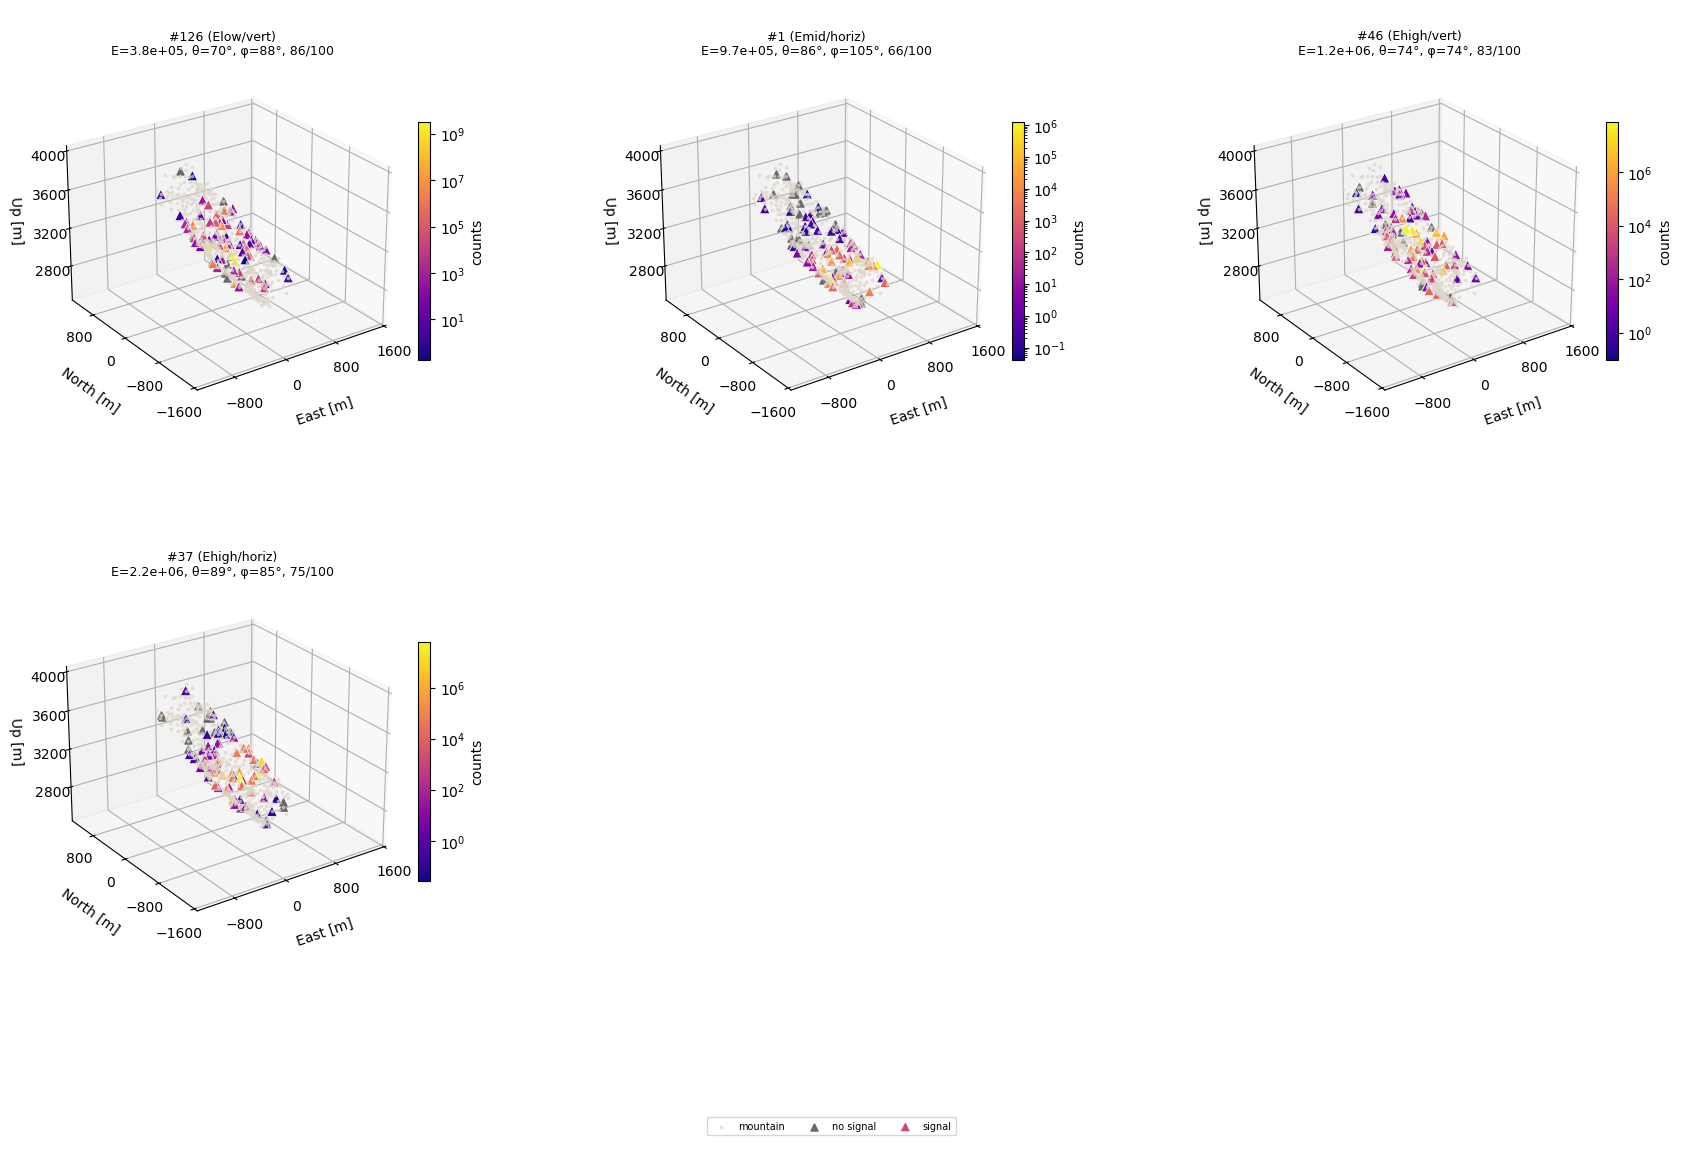

In [14]:
import importlib.util as _ilu
from matplotlib.ticker import MaxNLocator
from plots.lib import geometry_plots

_spec = _ilu.spec_from_file_location("opt_plotting",
                                     os.path.join(_V6, "plots", "lib", "opt_plotting.py"))
_optplt = _ilu.module_from_spec(_spec); _spec.loader.exec_module(_optplt)

MTN_ENU  = _optplt.mountain_enu(mountain)   # (n, 3) East, North, Up
SURF_CPU = surface.to("cpu")                # projection is a read-only plotting step
P_dec    = positions.numpy()                # (S, 3) real decay vertices

# Half-width [m] of the East/North box drawn around the array centre -- same
# framing choice as explore_trigger_counts.ipynb's detector-pattern figure.
VIEW_R = 1500.0
CTR = MTN_ENU.mean(axis=0)
UP_LO, UP_HI = MTN_ENU[:, 2].min() - 300.0, MTN_ENU[:, 2].max() + 300.0

# The surrogate's forward_sample() draw can put one detector's predicted
# count or arrival time orders of magnitude from the rest (a reparameterized
# noise draw, not a bounded kernel label -- see diag_stage3.py's finding that
# ~1/3 of "sample"-regime slots come back negative). A literal min/max colour
# scale then spends almost its whole range on that one outlier and renders
# everything else as flat colour. Clipping the COLOUR range (not the
# live/dark split, which stays threshold-based) to a percentile of the live
# population keeps the outlier from washing out the pattern.
PCT_CLIP = (2.0, 98.0)      # energy figure below
# Arrival time is noisier still -- E is a sum over many kernel weights so a
# single stray point barely moves it, but T is picked out of a `randn` draw
# directly (dual.forward_sample's reparameterized eps*std term), so its outlier
# tail is fatter. A tighter clip is what actually keeps the front-timing
# structure across the array visible instead of two or three outliers washing
# the rest into one colour.
T_PCT_CLIP = (10.0, 90.0)   # arrival-time figure below

def _in_view(P):
    return ((np.abs(P[:, 0] - CTR[0]) <= VIEW_R)
            & (np.abs(P[:, 1] - CTR[1]) <= VIEW_R)
            & (P[:, 2] >= UP_LO) & (P[:, 2] <= UP_HI))


class _NoClouds:
    """Passed as `points` to `plot_detector_patterns`/`_by_time`: Stage 2 never
    sees a point cloud, so every index returns None and `panel`'s `cloud=None`
    branch simply skips the cloud scatter (same branch explore_trigger_counts.py's
    panel takes when it has nothing to draw there)."""
    def __getitem__(self, i):
        return None

NO_CLOUDS = _NoClouds()


def panel(ax, E_arr, e_det, n_det_xy, cloud=None, s=None):
    """One 3D ENU panel: mountain + decay vertex + detectors by predicted count.

    `cloud` is accepted only for signature parity with
    explore_trigger_counts.ipynb's `panel` (`plot_detector_patterns` always
    passes one) -- it is always None here.
    """
    ax.scatter(MTN_ENU[:, 0], MTN_ENU[:, 1], MTN_ENU[:, 2], s=3, c="#DDD6C9",
               alpha=0.6, depthshade=False, label="mountain")
    if s is not None and _in_view(P_dec[s][None, :])[0]:
        ax.scatter(*P_dec[s], c="red", s=110, marker="*", depthshade=False,
                   label="decay vertex")

    sc, n_live, n_over = _optplt.draw_detectors_enu_3d(
        ax, E_arr, e_det, n_det_xy, SURF_CPU,
        layout_threshold=LAYOUT_THRESHOLD, log1p_space=False, pct_clip=PCT_CLIP)

    ax.set_xlim(CTR[0] - VIEW_R, CTR[0] + VIEW_R)
    ax.set_ylim(CTR[1] - VIEW_R, CTR[1] + VIEW_R)
    ax.set_zlim(UP_LO, UP_HI)
    ax.set_xlabel("East [m]", labelpad=8)
    ax.set_ylabel("North [m]", labelpad=8)
    ax.set_zlabel("Up [m]", labelpad=2)
    ax.tick_params(axis="x", pad=2); ax.tick_params(axis="y", pad=2)
    ax.tick_params(axis="z", pad=0)
    for a in (ax.xaxis, ax.yaxis, ax.zaxis):
        a.set_major_locator(MaxNLocator(nbins=4))
    ax.view_init(elev=25, azim=-125)
    return sc, n_live, n_over

EXAMPLE_STRATEGY = 'center_gauss400'
fig = geometry_plots.plot_detector_patterns(
    panel, df, df_show, layouts_cache, points=NO_CLOUDS,
    example_strategy=EXAMPLE_STRATEGY, layout_threshold=LAYOUT_THRESHOLD)
with plt.rc_context({'savefig.bbox': 'tight', 'savefig.pad_inches': 0.3}):
    plt.show()


## Detector patterns, coloured by predicted arrival time (Stage 2 surrogate)

Same six representative (shower, layout) picks and the same 3D ENU view as the figure
above, but detectors are coloured by the **surrogate's predicted arrival time** instead of
predicted counts, on a linear (not log) scale in µs — see
`explore_trigger_counts.ipynb`'s matching time-colored cell for why linear. The dark/lit
split is still `E`-derived, so both figures here show the identical lit set; only the
colour channel differs.

Both figures clip their colour range to a percentile of the live population rather than
the literal min/max — a `forward_sample()` draw can put one detector's predicted value
orders of magnitude from the rest, and an unclipped scale then spends nearly its whole
range on that one point. Arrival time uses a tighter clip than energy (`T_PCT_CLIP` =
(10, 90) vs `PCT_CLIP` = (2, 98)): `T` comes straight out of the reparameterized noise
draw, so its outlier tail is fatter than the summed, self-averaging `E` channel's.


/n/home05/zdimitrov/tambo/TambOpt/plots/lib/geometry_plots.py:391: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(pad=1.2)


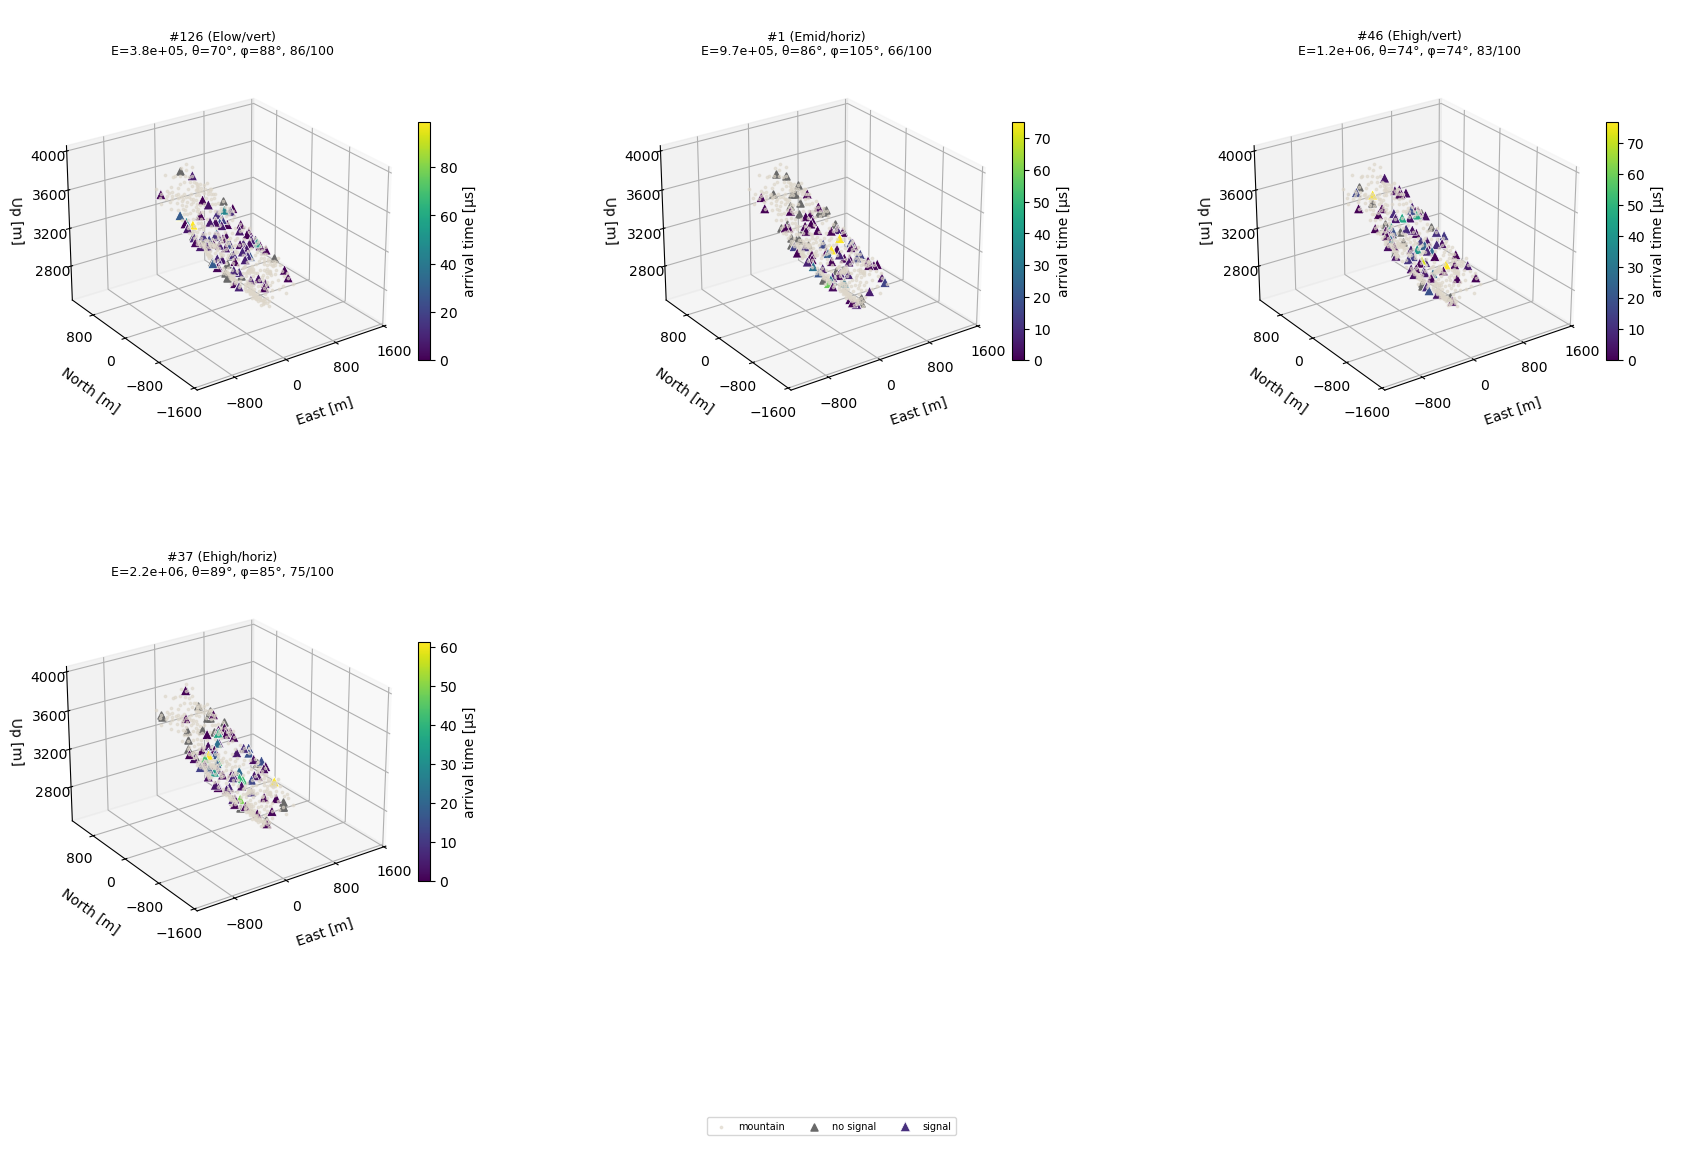

In [15]:
def panel_time(ax, E_arr, T_arr, e_det, n_det_xy, cloud=None, s=None):
    """Twin of `panel` above, coloured by the surrogate's predicted arrival time
    instead of predicted counts. `cloud` is accepted for signature parity only
    -- see `panel`."""
    ax.scatter(MTN_ENU[:, 0], MTN_ENU[:, 1], MTN_ENU[:, 2], s=3, c="#DDD6C9",
               alpha=0.6, depthshade=False, label="mountain")
    if s is not None and _in_view(P_dec[s][None, :])[0]:
        ax.scatter(*P_dec[s], c="red", s=110, marker="*", depthshade=False,
                   label="decay vertex")

    sc, n_live, n_over = _optplt.draw_detectors_enu_3d_by_time(
        ax, E_arr, T_arr, e_det, n_det_xy, SURF_CPU,
        layout_threshold=LAYOUT_THRESHOLD, pct_clip=T_PCT_CLIP)

    ax.set_xlim(CTR[0] - VIEW_R, CTR[0] + VIEW_R)
    ax.set_ylim(CTR[1] - VIEW_R, CTR[1] + VIEW_R)
    ax.set_zlim(UP_LO, UP_HI)
    ax.set_xlabel("East [m]", labelpad=8)
    ax.set_ylabel("North [m]", labelpad=8)
    ax.set_zlabel("Up [m]", labelpad=2)
    ax.tick_params(axis="x", pad=2); ax.tick_params(axis="y", pad=2)
    ax.tick_params(axis="z", pad=0)
    for a in (ax.xaxis, ax.yaxis, ax.zaxis):
        a.set_major_locator(MaxNLocator(nbins=4))
    ax.view_init(elev=25, azim=-125)
    return sc, n_live, n_over

fig = geometry_plots.plot_detector_patterns_by_time(
    panel_time, df, df_show, layouts_cache_time, points=NO_CLOUDS,
    example_strategy=EXAMPLE_STRATEGY, layout_threshold=LAYOUT_THRESHOLD)
with plt.rc_context({'savefig.bbox': 'tight', 'savefig.pad_inches': 0.3}):
    plt.show()
